## Verificar os dados

In [1]:
%pip install -r requirements.txt

from pathlib import Path

# Este notebook usa o ficheiro limpo que o 01_EDA grava no fim
LIMPO = Path("data/kingcounty/kc_clean.csv")
if not LIMPO.exists():
    raise FileNotFoundError(f"{LIMPO} não existe. Executa primeiro o notebook 01_EDA.")

print("Dataset limpo em:", LIMPO)


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /Users/anytng/Developer/Universidade/Masters/FundamentalsOfAI/FAI26_P02_G09/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Dataset limpo em: data/kingcounty/kc_clean.csv


## Objetivo

Queremos agrupar as casas vendidas no condado de King em tipos de casa, pelo tamanho da casa e do terreno, pelo número de andares e pelo ano da última obra. Isto ajuda uma agência ou um avaliador a organizar as casas por tipo e a comparar cada casa com outras do mesmo tipo.

Usa o `kc_clean.csv` gerado pelo `01_EDA`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from libs.kmeans import KMeans, silhouette, rand_ajustado

SEMENTE = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Cores dos gráficos, as mesmas do 02_classify
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#a3a29c"
TEXTO, TEXTO_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TEXTO, "axes.titlelocation": "left",
})

## Carregar os dados

Algumas casas foram vendidas mais de uma vez. Ficamos com a última venda de cada casa, para uma casa revendida não contar duas vezes, e verificamos se as variáveis usadas mudam entre as vendas da mesma casa.

In [3]:
vendas = pd.read_csv(LIMPO, parse_dates=["date"])
VARIAVEIS = ["AreaCasa", "AreaTerreno", "floors", "AnoUltimaObra"]

repetidas = vendas[vendas.duplicated("id", keep=False)]
mudam = repetidas.groupby("id")[VARIAVEIS].nunique().gt(1)
casas = vendas.sort_values(["id", "date"]).drop_duplicates("id", keep="last").reset_index(drop=True)

pd.Series({
    "vendas": len(vendas),
    "casas com mais de uma venda": repetidas["id"].nunique(),
    "casas que mudam nas variáveis usadas": int(mudam.any(axis=1).sum()),
    "casas usadas": len(casas),
}).to_frame("valor")

,valor
vendas,21613
casas com mais de uma venda,176
casas que mudam nas variáveis usadas,0
casas usadas,21436


Das 21 613 vendas ficam 21 436 casas. Há 176 casas com mais de uma venda e nenhuma muda nas variáveis usadas entre vendas.

## Escolher e preparar as variáveis

Usamos quatro variáveis, `AreaCasa`, a área da casa, `AreaTerreno`, a área do terreno, as duas em m², `floors`, o número de andares, e `AnoUltimaObra`, que é o ano da renovação ou o da construção se a casa nunca foi renovada. Testámos também com os quartos, as casas de banho, a qualidade da construção e o estado de conservação, mas os clusters ficavam mais misturados, com silhouette de 0,25 contra 0,35. Os quartos e as casas de banho dizem quase o mesmo que a área. O preço e a localização ficam de fora porque queremos grupos de casas parecidas e não de preços ou zonas parecidas. Estas variáveis que ficam de fora servem no fim para descrever os clusters.

Não há valores em falta. Aplicamos o log às duas áreas e pomos as quatro variáveis na mesma escala, subtraindo a média e dividindo pelo desvio padrão.

In [4]:
valores = casas[VARIAVEIS].astype(float)
pd.DataFrame({
    "em falta": valores.isna().sum(),
    "zeros": valores.eq(0).sum(),
    "mínimo": valores.min(),
    "mediana": valores.median(),
    "máximo": valores.max(),
})

,em falta,zeros,mínimo,mediana,máximo
AreaCasa,0,0,26.941882,178.373837,1257.907162
AreaTerreno,0,0,48.309581,707.363747,153416.271231
floors,0,0,1.000000,1.500000,3.500000
AnoUltimaObra,0,0,1900.000000,1978.000000,2015.000000


In [5]:
transformados = valores.copy()
transformados[["AreaCasa", "AreaTerreno"]] = np.log(transformados[["AreaCasa", "AreaTerreno"]])
X = ((transformados - transformados.mean()) / transformados.std(ddof=0)).to_numpy()
print("Matriz:", X.shape)

Matriz: (21436, 4)


## Implementar o K-Means

O K-Means está na classe `KMeans` de `libs/kmeans.py`, feita só com NumPy. Cada tentativa começa com K casas sorteadas como centros e repete dois passos, juntar cada casa ao centro mais próximo e recalcular cada centro como a média das suas casas, até os grupos deixarem de mudar, com um máximo de 300 iterações. Se um cluster ficar vazio, o seu centro passa para a casa mais afastada dos outros centros. Fazemos 10 tentativas para cada K e ficamos com a de menor inércia. No mesmo ficheiro estão a silhouette e o índice de Rand ajustado.

## Escolher o número de clusters

Corremos o K-Means com K de 2 a 8 e comparamos a inércia e a silhouette. A silhouette é calculada numa amostra de 2000 casas, a mesma para todos os K, porque com as 21 436 casas o cálculo das distâncias entre todos os pares ficaria muito pesado.

Escolhemos o K do cotovelo da inércia, o K a partir do qual a inércia passa a descer muito menos. Para isso comparamos quanto a inércia desce ao chegar a cada K com quanto desce no K seguinte.

In [6]:
KS = range(2, 9)
amostra = np.random.default_rng(SEMENTE).choice(len(X), 2000, replace=False)

modelos = {}
linhas = []
for k in KS:
    modelos[k] = KMeans(k, n_init=10, random_state=SEMENTE).fit(X)
    linhas.append({
        "K": k,
        "inércia": modelos[k].inertia_,
        "silhouette": silhouette(X[amostra], modelos[k].labels_[amostra]),
        "menor cluster": np.bincount(modelos[k].labels_).min(),
        "tentativas que convergiram": int(modelos[k].tentativas_["convergiu"].sum()),
    })
comparacao = pd.DataFrame(linhas).set_index("K")

# Quanto a inércia desce ao passar de K-1 para K, e quantas vezes isso é mais do que desce no K seguinte
comparacao["descida"] = -comparacao["inércia"].diff()
comparacao["descida / seguinte"] = comparacao["descida"] / comparacao["descida"].shift(-1)
K_ESCOLHIDO = int(comparacao["descida / seguinte"].idxmax())
print("K escolhido:", K_ESCOLHIDO)
comparacao.round(3)

K escolhido: 6


,inércia,silhouette,menor cluster,tentativas que convergiram,descida,descida / seguinte
K,,,,,,
2,54626.189,0.367,9033,10,NaN,NaN
3,43147.704,0.365,3349,10,11478.486,1.569
4,35831.732,0.315,2600,10,7315.972,1.147
5,29455.838,0.332,1777,10,6375.894,1.466
6,25105.246,0.345,1738,10,4350.592,2.013
7,22943.922,0.318,1204,10,2161.324,1.077
8,20937.230,0.265,1371,10,2006.692,NaN


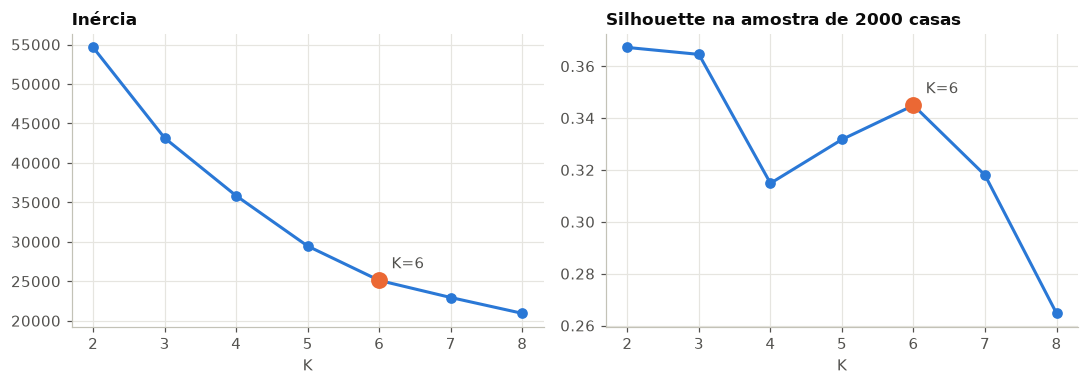

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, coluna, titulo in [(eixos[0], "inércia", "Inércia"), (eixos[1], "silhouette", "Silhouette na amostra de 2000 casas")]:
    ax.plot(comparacao.index, comparacao[coluna], color=AZUL, lw=2, marker="o", ms=6)
    ax.plot(K_ESCOLHIDO, comparacao.loc[K_ESCOLHIDO, coluna], "o", color=LARANJA, ms=10, zorder=3)
    ax.annotate(f"K={K_ESCOLHIDO}", (K_ESCOLHIDO, comparacao.loc[K_ESCOLHIDO, coluna]),
                xytext=(8, 8), textcoords="offset points", color=TEXTO_2)
    ax.set_xticks(list(KS))
    ax.set_xlabel("K")
    ax.set_title(titulo)
fig.tight_layout()
plt.show()

A inércia desce 4 351 de K=5 para K=6 e só 2 161 de K=6 para K=7, a maior diferença entre um K e o seguinte, por isso o cotovelo é em K=6. A silhouette é mais alta com K=2 e K=3, 0,37, e entre K=4 e K=8 tem o pico em K=6, com 0,35. Ficamos com K=6, que é o cotovelo e tem silhouette perto da de K=2 e K=3. Todas as tentativas convergiram.

## Descrever os clusters

Para cada cluster mostramos o número de casas e a mediana e os percentis 25 e 75 de cada variável, nas unidades originais. O mapa de calor mostra os centros na escala usada no K-Means.

In [8]:
melhor = modelos[K_ESCOLHIDO]

# Numeramos os clusters da menor para a maior área, para a numeração não depender do sorteio
ordem = np.argsort(melhor.cluster_centers_[:, VARIAVEIS.index("AreaCasa")])
novo_numero = np.empty(K_ESCOLHIDO, dtype=int)
novo_numero[ordem] = np.arange(K_ESCOLHIDO)
casas["Cluster"] = novo_numero[melhor.labels_]
centros = pd.DataFrame(melhor.cluster_centers_[ordem], columns=VARIAVEIS)

# Os perfis usam os valores antes do log e da mudança de escala
tamanhos = casas.groupby("Cluster").size()
perfil = casas.groupby("Cluster")[VARIAVEIS].median()
perfil.insert(0, "casas", tamanhos)
perfil.insert(1, "% das casas", tamanhos / len(casas) * 100)
perfil.round(1)

,casas,% das casas,AreaCasa,AreaTerreno,floors,AnoUltimaObra
Cluster,,,,,,
0,3833,17.9,101.3,668.9,1.0,1949.0
1,1853,8.6,136.6,147.7,2.0,2006.0
2,2011,9.4,174.7,464.5,1.5,1922.0
3,6190,28.9,177.4,833.9,1.0,1969.0
4,5811,27.1,240.6,682.8,2.0,2000.0
5,1738,8.1,259.2,4608.0,2.0,1987.0


In [9]:
print("Percentis 25 e 75 de cada variável em cada cluster")
casas.groupby("Cluster")[VARIAVEIS].quantile([0.25, 0.75]).unstack().round(1)

Percentis 25 e 75 de cada variável em cada cluster


AreaCasa        AreaTerreno         floors      AnoUltimaObra        
            0.25   0.75        0.25    0.75   0.25 0.75          0.25    0.75
Cluster                                                                      
0           86.4  117.1       479.1   822.5    1.0  1.0        1941.0  1959.0
1          118.9  155.1       111.7   250.8    2.0  3.0        2002.0  2009.0
2          144.9  216.5       371.6   573.8    1.5  2.0        1911.0  1929.0
3          151.4  213.7       682.8  1066.0    1.0  1.0        1960.0  1980.0
4          198.8  293.6       501.5   922.5    2.0  2.0        1990.0  2006.0
5          205.3  332.6      3333.6  9805.4    1.0  2.0        1977.0  1995.0

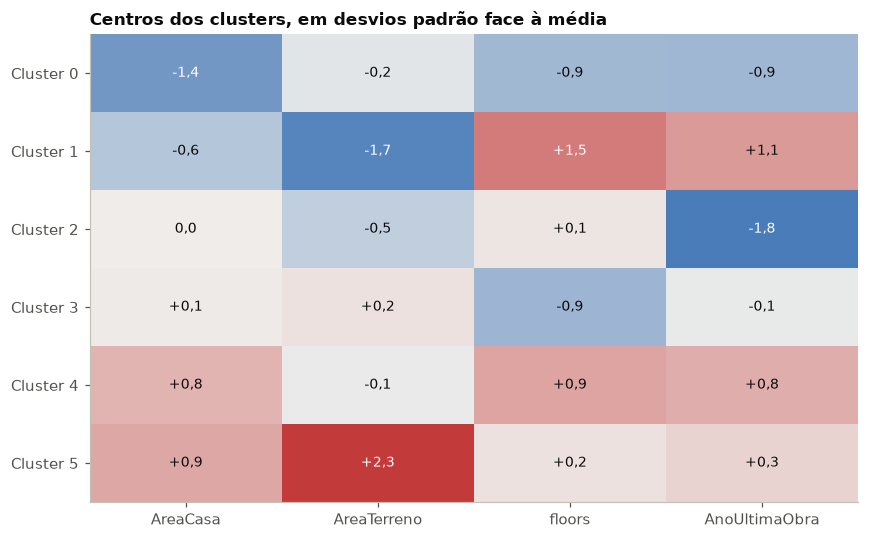

In [10]:
# Azul abaixo da média, cinzento na média e vermelho acima
divergente = LinearSegmentedColormap.from_list("divergente", ["#1c5cab", "#f0efec", "#c23b3a"])
limite = np.abs(centros.to_numpy()).max()

fig, ax = plt.subplots(figsize=(8, 0.6 * K_ESCOLHIDO + 1.4))
ax.imshow(centros, cmap=divergente, vmin=-limite, vmax=limite, aspect="auto")
for i in range(K_ESCOLHIDO):
    for j in range(len(VARIAVEIS)):
        valor = centros.iloc[i, j]
        ax.text(j, i, f"{valor:+.1f}".replace(".", ",").replace("-0,0", "0,0").replace("+0,0", "0,0"), ha="center", va="center", fontsize=9,
                color="white" if abs(valor) > 0.55 * limite else TEXTO)
ax.set_xticks(range(len(VARIAVEIS)), VARIAVEIS)
ax.set_yticks(range(K_ESCOLHIDO), [f"Cluster {i}" for i in range(K_ESCOLHIDO)])
ax.grid(False)
ax.set_title("Centros dos clusters, em desvios padrão face à média")
fig.tight_layout()
plt.show()

Os seis clusters são tipos de casa diferentes:

- Cluster 0, casas pequenas e antigas de um piso, com mediana de 101 m² e última obra em 1949.
- Cluster 1, moradias em banda recentes, com 137 m², dois ou três pisos, última obra em 2006 e um terreno muito pequeno, com mediana de 148 m².
- Cluster 2, casas antigas de um piso e meio, com 175 m² e última obra em 1922.
- Cluster 3, casas de um piso dos anos 60 e 70, com 177 m². É o maior, com 29% das casas.
- Cluster 4, casas recentes de dois pisos, com 241 m² e última obra em 2000.
- Cluster 5, casas com terreno grande, com mediana de 4 608 m² de terreno e 259 m² de casa.

A seguir descrevemos os clusters com variáveis que não entraram no K-Means, o preço da última venda, os quartos, as casas de banho, a qualidade da construção, o estado de conservação, o ano de construção, a percentagem de casas renovadas, com vista e com frente de água, e os códigos postais mais comuns.

In [11]:
contexto = casas.groupby("Cluster").agg(
    preco_mediano=("price", "median"),
    preco_p25=("price", lambda s: s.quantile(0.25)),
    preco_p75=("price", lambda s: s.quantile(0.75)),
    quartos=("bedrooms", "median"),
    casas_banho=("bathrooms", "median"),
    qualidade=("grade", "median"),
    estado=("condition", "median"),
    ano_construcao=("yr_built", "median"),
    pct_renovadas=("Renovada", "mean"),
    pct_vista=("view", lambda s: s.gt(0).mean()),
    pct_frente_agua=("waterfront", "mean"),
)
contexto[["pct_renovadas", "pct_vista", "pct_frente_agua"]] *= 100
contexto.round(1)

,preco_mediano,preco_p25,preco_p75,quartos,casas_banho,qualidade,estado,ano_construcao,pct_renovadas,pct_vista,pct_frente_agua
Cluster,,,,,,,,,,,
0,310000.0,229000.0,415000.0,3.0,1.0,7.0,3.0,1949.0,2.0,4.1,0.3
1,409000.0,325000.0,512500.0,3.0,2.5,8.0,3.0,2006.0,2.5,3.0,0.1
2,599000.0,455000.0,762000.0,3.0,1.8,7.0,4.0,1922.0,0.1,13.2,0.6
3,420000.0,302350.0,570000.0,3.0,2.0,7.0,3.0,1968.0,4.8,11.4,0.5
4,565000.0,387927.5,799000.0,4.0,2.5,8.0,3.0,1999.0,6.5,11.0,1.0
5,616875.0,470000.0,850000.0,4.0,2.5,8.0,3.0,1985.0,6.4,16.7,2.7


In [12]:
print("Três códigos postais mais comuns em cada cluster")
por_codigo = casas.groupby(["Cluster", "zipcode"]).size().rename("casas").reset_index()
por_codigo["% do cluster"] = por_codigo["casas"] / por_codigo["Cluster"].map(tamanhos) * 100
por_codigo.sort_values(["Cluster", "casas"], ascending=[True, False]).groupby("Cluster").head(3).round(1)

Três códigos postais mais comuns em cada cluster


,Cluster,zipcode,casas,% do cluster
52,0,98118,178,4.6
51,0,98117,173,4.5
49,0,98115,170,4.4
103,1,98103,192,10.4
106,1,98107,106,5.7
120,1,98144,102,5.5
161,2,98103,207,10.3
170,2,98117,168,8.4
168,2,98115,159,7.9
211,3,98034,290,4.7


O preço não acompanha o tamanho da casa. O cluster 2, de casas de 1922, tem preço mediano de 599 000 dólares, quase igual aos 617 000 do cluster 5, das casas com terreno grande, e bem acima dos 420 000 do cluster 3, com casas do mesmo tamanho. O cluster 2 é também o que tem o estado de conservação mais alto, com mediana 4. As casas mais baratas são as do cluster 0, com 310 000. Os quartos e a qualidade da construção mudam pouco entre clusters, com medianas de 3 ou 4 quartos e qualidade 7 ou 8.

Os clusters 0, 1 e 2 ficam em Seattle, nos códigos postais 98103, 98107, 98115, 98117, 98118 e 98144. O cluster 3 aparece mais em Kirkland, Federal Way e Bellevue, o 4 em Maple Valley, Sammamish e Redmond e o 5 em Redmond, Woodinville e Issaquah. O cluster 5 tem também mais casas com vista, 17%, e com frente de água, 2,7%.

## Testar a estabilidade

Para ver se o resultado depende dos centros sorteados no início, repetimos o K-Means com as sementes 43 a 46 e comparamos cada partição com a da semente 42 pelo índice de Rand ajustado. O índice é 1 quando as duas partições juntam as mesmas casas.

In [13]:
estabilidade = []
for semente in range(SEMENTE + 1, SEMENTE + 5):
    modelo = KMeans(K_ESCOLHIDO, n_init=10, random_state=semente).fit(X)
    estabilidade.append({
        "semente": semente,
        "inércia": modelo.inertia_,
        "índice de Rand ajustado": rand_ajustado(melhor.labels_, modelo.labels_),
    })
pd.DataFrame(estabilidade).round(4)

,semente,inércia,índice de Rand ajustado
0,43,25105.2504,0.9997
1,44,25105.2509,0.9995
2,45,25105.2550,0.9998
3,46,25105.2509,0.9995


Com as outras quatro sementes a inércia é praticamente igual e o índice de Rand ajustado fica acima de 0,999, por isso os clusters não dependem do sorteio inicial.

## Conclusão

Com a área da casa e do terreno, o número de andares e o ano da última obra, o K-Means com K=6 separa as casas em seis tipos, casas pequenas e antigas, moradias em banda recentes, casas antigas de um piso e meio, casas de um piso dos anos 60 e 70, casas recentes de dois pisos e casas com terreno grande. K=6 é o cotovelo da inércia, a silhouette é 0,35 e os clusters repetem-se com outras sementes. A localização não entrou no K-Means, mas os três primeiros tipos ficam em Seattle e os outros três fora da cidade. O preço também não entrou, e as casas antigas de Seattle valem quase tanto como as casas com terreno grande.

Os clusters dependem das variáveis escolhidas e do K. A silhouette é parecida entre K=2 e K=6, por isso as fronteiras entre tipos não são muito marcadas e há casas que ficam perto de dois clusters. Os andares só têm seis valores diferentes e pesam tanto como as áreas na distância.